In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Crossover": root / "Crossover",
    "Population_500": root / "Population" / "500",
}
dataframes=[]
for source_name, folder in sources.items():
    csv_files = sorted(folder.rglob("*.csv"))
    print(f"{source_name}: ditemukan {len(csv_files)} file CSV")

    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

Crossover: ditemukan 36 file CSV
Population_500: ditemukan 12 file CSV


In [6]:
df_M01_crossover=df_all[df_all["model_id"]=="M01"].copy()
summary_M01_Crossover=df_M01_crossover.groupby(["grid_rows", "pc", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
)
display(summary_M01_Crossover)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.516667,2.500000,2.600000,0.037905,30
1,10,0.80,Maze,3.333333,3.333333,3.333333,0.000000,30
2,10,0.80,Random,2.598810,2.416667,2.928571,0.161607,60
3,10,0.85,Cluster,2.510000,2.500000,2.600000,0.030513,30
4,10,0.85,Maze,3.338889,3.333333,3.500000,0.030429,30
5,10,0.85,Random,2.605159,2.416667,2.785714,0.146463,60
6,10,0.90,Cluster,2.510000,2.500000,2.600000,0.030513,30
7,10,0.90,Maze,3.344444,3.333333,3.500000,0.042285,30
8,10,0.90,Random,2.591468,2.416667,2.785714,0.153186,60
9,10,0.95,Cluster,2.523333,2.500000,2.600000,0.043018,30


In [8]:
table_random=summary_M01_Crossover[summary_M01_Crossover["map_type"]=="Random"].sort_values("pc")
display(table_random)
table_cluster=summary_M01_Crossover[summary_M01_Crossover["map_type"]=="Cluster"].sort_values("pc")
display(table_cluster)
table_Maze=summary_M01_Crossover[summary_M01_Crossover["map_type"]=="Maze"].sort_values("pc")
display(table_Maze)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.80,Random,2.598810,2.416667,2.928571,0.161607,60
14,20,0.80,Random,6.249551,6.025000,6.512821,0.216806,60
26,40,0.80,Random,6.682759,6.525641,6.856250,0.103600,60
17,20,0.85,Random,6.250395,6.025000,6.538462,0.217236,60
29,40,0.85,Random,6.686795,6.525641,6.856250,0.102020,60
5,10,0.85,Random,2.605159,2.416667,2.785714,0.146463,60
20,20,0.90,Random,6.247874,6.025000,6.512821,0.217688,60
8,10,0.90,Random,2.591468,2.416667,2.785714,0.153186,60
32,40,0.90,Random,6.686830,6.532051,6.881250,0.109777,60
11,10,0.95,Random,2.597817,2.416667,2.857143,0.154911,60


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.516667,2.500000,2.600000,0.037905,30
12,20,0.80,Cluster,4.799099,4.783784,4.918919,0.028108,30
24,40,0.80,Cluster,5.491828,5.445161,5.683871,0.047370,30
15,20,0.85,Cluster,4.796396,4.783784,4.837838,0.018417,30
27,40,0.85,Cluster,5.473333,5.445161,5.529032,0.020576,30
3,10,0.85,Cluster,2.510000,2.500000,2.600000,0.030513,30
18,20,0.90,Cluster,4.797297,4.783784,4.864865,0.019759,30
6,10,0.90,Cluster,2.510000,2.500000,2.600000,0.030513,30
30,40,0.90,Cluster,5.499140,5.445161,5.606452,0.045002,30
9,10,0.95,Cluster,2.523333,2.500000,2.600000,0.043018,30


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.80,Maze,3.333333,3.333333,3.333333,0.000000,30
13,20,0.80,Maze,6.818803,6.794872,6.871795,0.023261,30
25,40,0.80,Maze,6.905747,6.834483,6.986207,0.045758,30
16,20,0.85,Maze,6.811111,6.794872,6.820513,0.012568,30
28,40,0.85,Maze,6.907816,6.841379,7.124138,0.061591,30
4,10,0.85,Maze,3.338889,3.333333,3.500000,0.030429,30
19,20,0.90,Maze,6.813675,6.794872,6.846154,0.016402,30
7,10,0.90,Maze,3.344444,3.333333,3.500000,0.042285,30
31,40,0.90,Maze,6.894713,6.834483,6.979310,0.039924,30
10,10,0.95,Maze,3.333333,3.333333,3.333333,0.000000,30


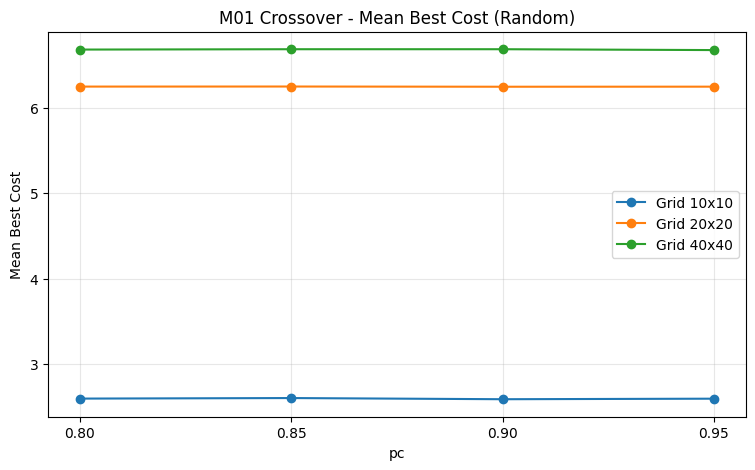

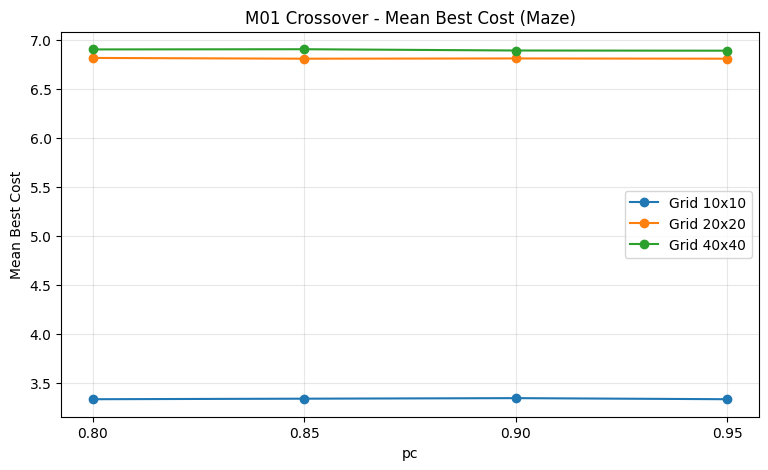

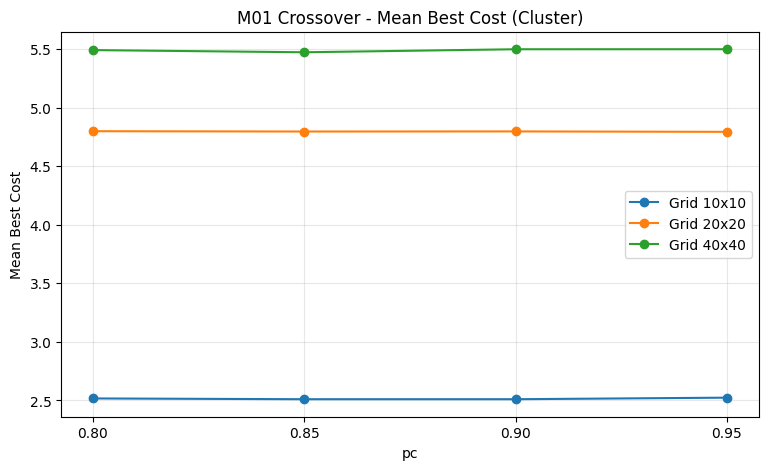

In [11]:
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M01_Crossover[
        summary_M01_Crossover["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pc")
        )

        plt.plot(
            data_size["pc"],
            data_size["mean_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M01 Crossover - Mean Best Cost ({map_type})")
    plt.xlabel("pc")
    plt.ylabel("Mean Best Cost")
    plt.xticks(sorted(data["pc"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [13]:
summary_M01_Crossover["rank_mean_cost"] = (
    summary_M01_Crossover
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M01 = (
    summary_M01_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_M01)

,pc,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
3,0.95,2.000000,5.041887,0.071926,9
1,0.85,2.666667,5.042211,0.071090,9
2,0.90,2.500000,5.042827,0.074948,9
0,0.80,2.833333,5.044066,0.073824,9


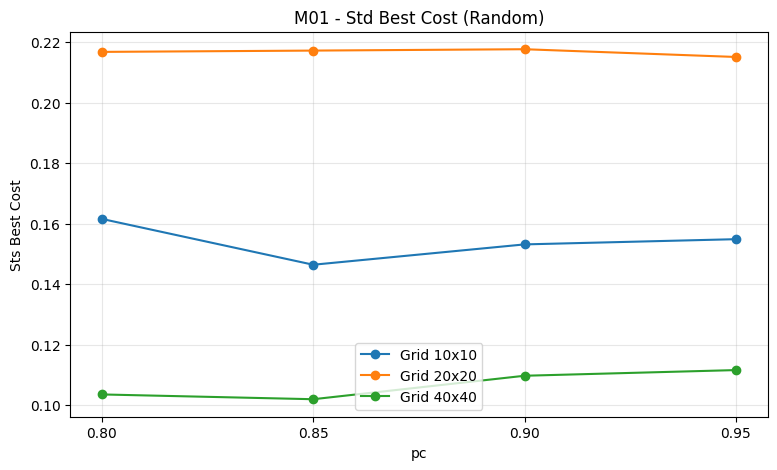

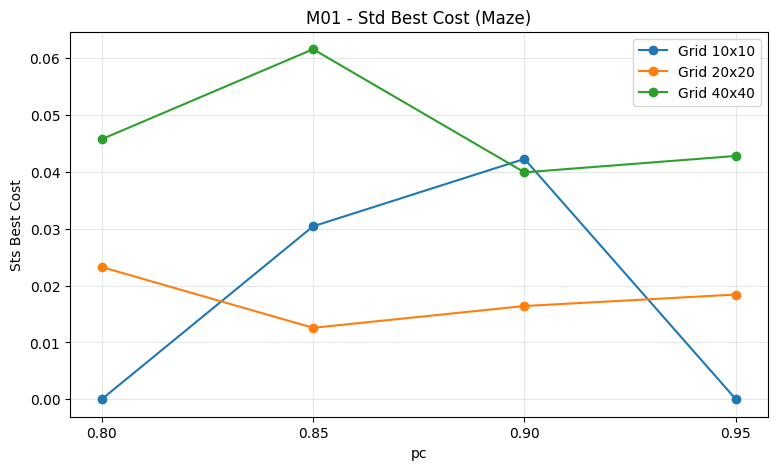

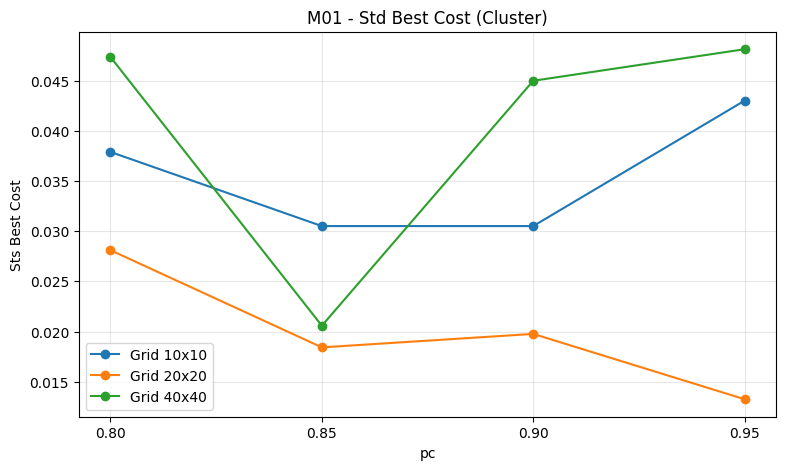

In [14]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M01_Crossover[
        summary_M01_Crossover["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pc")
        )

        plt.plot(
            data_size["pc"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M01 - Std Best Cost ({map_type})")
    plt.xlabel("pc")
    plt.ylabel("Sts Best Cost")
    plt.xticks(sorted(data["pc"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [15]:
summary_M01_Crossover["rank_std_cost"] = (
    summary_M01_Crossover
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M01_std = (
    summary_M01_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values([ "avg_std_cost"])
)

print(avg_rank_M01_std)

     pc  avg_rank_std  avg_std_cost  jumlah_kombinasi
1  0.85      2.000000      0.071090                 9
3  0.95      2.611111      0.071926                 9
0  0.80      2.944444      0.073824                 9
2  0.90      2.444444      0.074948                 9


In [18]:
summary_M01_time_crossover=(df_M01_crossover.groupby(["grid_rows","pc", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M01_time_crossover)

avg_time_by_population_m01 = (
    summary_M01_time_crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values("avg_execTime")
)
display(avg_time_by_population_m01)
summary_time_pivot = summary_M01_time_crossover.pivot(
    index=["grid_rows", "pc"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M01_time_crossover
    .groupby(["map_type", "pc"], as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pc,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.80,Cluster,39.733333,15,132,35.626350,30
1,10,0.80,Maze,30.400000,11,101,26.113281,30
2,10,0.80,Random,38.200000,11,130,28.939329,60
3,10,0.85,Cluster,76.700000,9,520,148.449957,30
4,10,0.85,Maze,87.266667,16,495,160.745662,30
5,10,0.85,Random,92.583333,13,553,153.601431,60
6,10,0.90,Cluster,94.433333,10,549,180.856522,30
7,10,0.90,Maze,76.933333,11,461,149.812051,30
8,10,0.90,Random,82.450000,10,501,139.756498,60
9,10,0.95,Cluster,83.166667,17,431,135.484338,30


,pc,avg_execTime,avg_std_time,jumlah_kombinasi
0,0.80,601.462963,105.801754,9
1,0.85,660.272222,221.108340,9
3,0.95,675.385185,224.697405,9
2,0.90,689.748148,280.653073,9


map_type            Cluster         Maze       Random
grid_rows pc                                         
10        0.80    39.733333    30.400000    38.200000
          0.85    76.700000    87.266667    92.583333
          0.90    94.433333    76.933333    82.450000
          0.95    83.166667    82.700000    87.816667
20        0.80   144.466667   113.466667   133.366667
          0.85   185.066667   170.533333   180.550000
          0.90   190.566667   192.000000   194.516667
          0.95   187.400000   189.766667   190.816667
40        0.80  1557.433333  1716.900000  1639.200000
          0.85  1878.166667  1574.900000  1696.683333
          0.90  1975.733333  1680.766667  1720.333333
          0.95  1690.700000  1540.800000  2025.300000

   map_type    pc  avg_execTime  avg_std_time  jumlah_kombinasi
0   Cluster  0.80    580.544444    109.304518                 3
3   Cluster  0.95    653.755556    230.798781                 3
1   Cluster  0.85    713.311111    209.740043                 3
2   Cluster  0.90    753.577778    280.919026                 3
7      Maze  0.95    604.422222    207.853925                 3
5      Maze  0.85    610.900000    204.067363                 3
4      Maze  0.80    620.255556    125.983380                 3
6      Maze  0.90    649.900000    328.948618                 3
8    Random  0.80    603.588889     82.117365                 3
9    Random  0.85    656.605556    249.517614                 3
10   Random  0.90    665.766667    232.091577                 3
11   Random  0.95    767.977778    235.439510                 3
